## **Importing Libraries & Data**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Data import
def get_my_data():
    url = "https://huggingface.co/datasets/Cainiao-AI/LaDe/resolve/main/delivery/delivery_sh.csv"
    df = pd.read_csv(url)
    return df
df = get_my_data()

In [ ]:
# Crear una copia profunda e independiente del DataFrame original
df_backup = df.copy()

print("Copia de seguridad creada exitosamente.")

Copia de seguridad creada exitosamente.


In [ ]:
# Sobrescribir 'df' con los datos exactos del respaldo
df = df_backup.copy()

print("DataFrame restaurado a su estado original.")

DataFrame restaurado a su estado original.


 ## **Data Cleaning**

In [ ]:
# Filtro 4: coordenadas dentro de Shanghai (bounding box aproximado)
bbox_lat = (30.6, 31.9)
bbox_lng = (120.8, 122.2)

# Definir total inicial de filas
n0 = len(df)

mask_bbox = (
    df['lat'].between(*bbox_lat) & df['lng'].between(*bbox_lng) &
    df['accept_gps_lat'].between(*bbox_lat) & df['accept_gps_lng'].between(*bbox_lng) &
    df['delivery_gps_lat'].between(*bbox_lat) & df['delivery_gps_lng'].between(*bbox_lng)
)

print(f"Filtro bounding box Shanghai: elimina {n0 - mask_bbox.sum()} filas")

Filtro bounding box Shanghai: elimina 316 filas


In [ ]:
df = df.drop(columns=['city', 'accept_gps_time', 'delivery_gps_time'])

In [ ]:
time_cols = ['accept_time', 'delivery_time']

for col in time_cols:
    df[col] = pd.to_datetime('2022-' + df[col].astype(str))

In [ ]:
# Generar una tabla resumen con las columnas y su número de valores únicos
resumen_unicos = pd.DataFrame({
    'columna': df.columns,
    'cantidad_unicos': [df[col].nunique() for col in df.columns]
})

# Mostrar la tabla ordenada de mayor a menor según la cantidad de únicos
resumen_unicos.sort_values(by='cantidad_unicos', ascending=False).reset_index(drop=True)

,columna,cantidad_unicos
0,order_id,1483864
1,delivery_time,144334
2,accept_time,130836
3,delivery_gps_lng,73503
4,lng,68747
5,delivery_gps_lat,58280
6,lat,56161
7,aoi_id,15564
8,courier_id,1733
9,accept_gps_lat,1252


 ## **Cluster Definition**

In [ ]:
import pandas as pd
from sklearn.cluster import DBSCAN

# 1. Definir columnas de origen
cols_accept = ['accept_gps_lng', 'accept_gps_lat']

# 2. Agrupar por las coordenadas exactas de aceptación y contar frecuencias
df_grouped = df.groupby(cols_accept).size().reset_index(name='frecuencia')

# 3. Aplicar DBSCAN sobre las coordenadas agrupadas (eps=0.015 equivale a ~78m)
db = DBSCAN(eps=0.00035, min_samples=1)
df_grouped['cluster_id'] = db.fit_predict(df_grouped[cols_accept])

# 4. Contar cuántos clusters únicos se generaron
total_clusters = df_grouped['cluster_id'].nunique()

print(f"Total de registros agrupados: {len(df_grouped)}")
print(f"Total de clusters generados: {total_clusters}")

# Mostrar las primeras filas de la tabla resultante
df_grouped.head()

Total de registros agrupados: 24748
Total de clusters generados: 60


,accept_gps_lng,accept_gps_lat,frecuencia,cluster_id
0,106.50668,29.58773,1,0
1,120.09755,30.29170,1,1
2,121.12841,31.17131,23,2
3,121.12841,31.17132,29,2
4,121.12841,31.17133,20,2


In [ ]:
# 1. Cruzar el cluster_id de vuelta al DataFrame principal (df)
cols_accept = ['accept_gps_lng', 'accept_gps_lat']
df = df.merge(df_grouped[cols_accept + ['cluster_id']], on=cols_accept, how='left')

# 2. Calcular los centroides (coordenadas promedio) de cada cluster
centroides = df.groupby('cluster_id')[cols_accept].transform('mean')

# 3. Asignar las coordenadas del centro como nuevas columnas
df['cluster_lng'] = centroides['accept_gps_lng']
df['cluster_lat'] = centroides['accept_gps_lat']

# 4. Verificar que las columnas se agregaron correctamente
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1483864 entries, 0 to 1483863
Data columns (total 17 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   order_id          1483864 non-null  int64         
 1   region_id         1483864 non-null  int64         
 2   courier_id        1483864 non-null  int64         
 3   lng               1483864 non-null  float64       
 4   lat               1483864 non-null  float64       
 5   aoi_id            1483864 non-null  int64         
 6   aoi_type          1483864 non-null  int64         
 7   accept_time       1483864 non-null  datetime64[ns]
 8   accept_gps_lng    1483864 non-null  float64       
 9   accept_gps_lat    1483864 non-null  float64       
 10  delivery_time     1483864 non-null  datetime64[ns]
 11  delivery_gps_lng  1483864 non-null  float64       
 12  delivery_gps_lat  1483864 non-null  float64       
 13  ds                1483864 non-null  int64 

In [ ]:
df.head()

,order_id,region_id,courier_id,lng,lat,aoi_id,aoi_type,accept_time,accept_gps_lng,accept_gps_lat,delivery_time,delivery_gps_lng,delivery_gps_lat,ds,cluster_id,cluster_lng,cluster_lat
0,3158819,1,164,121.52128,31.06614,450,1,2022-06-04 11:05:00,121.52281,31.10598,2022-06-04 17:40:00,121.52407,31.06614,604,44,121.5228,31.106
1,751342,1,164,121.52124,31.06687,450,1,2022-06-04 11:18:00,121.52286,31.10599,2022-06-04 15:06:00,121.52412,31.06618,604,44,121.5228,31.106
2,3380476,1,164,121.52106,31.06731,450,1,2022-06-03 10:13:00,121.52285,31.10591,2022-06-03 15:11:00,121.52059,31.06672,603,44,121.5228,31.106
3,2184571,1,164,121.52128,31.06616,450,1,2022-06-04 10:39:00,121.52282,31.10593,2022-06-04 15:41:00,121.52280,31.10542,604,44,121.5228,31.106
4,941371,1,164,121.52123,31.06614,450,1,2022-06-04 11:18:00,121.52285,31.10593,2022-06-04 14:07:00,121.52290,31.06758,604,44,121.5228,31.106


In [ ]:
def dtview(data):
    """Genera un DataFrame resumen optimizado con tipo de dato, nulos,
    valores únicos, mínimo y máximo para cada columna."""

    # Operaciones vectorizadas sobre todo el DataFrame a la vez
    nulos = data.isnull().sum()
    unicos = data.nunique()
    minimos = data.min(numeric_only=False)
    maximos = data.max(numeric_only=False)

    # Construcción directa usando las series indexing por columna
    resumen = pd.DataFrame({
        'Columna': data.columns,
        'Tipo_Dato': data.dtypes.values,
        'Nulos': nulos.values,
        'Valores_Unicos': unicos.values,
        'Minimo': minimos.values,
        'Maximo': maximos.values
    })

    return resumen

In [ ]:
dtview(df)

,Columna,Tipo_Dato,Nulos,Valores_Unicos,Minimo,Maximo
0,order_id,int64,0,1483864,2,4514655
1,region_id,int64,0,52,1,160
2,courier_id,int64,0,1733,0,4874
3,lng,float64,0,68747,102.08492,121.95474
4,lat,float64,0,56161,26.69903,39.9119
5,aoi_id,int64,0,15564,1,60147
6,aoi_type,int64,0,16,0,15
7,accept_time,datetime64[ns],0,130836,2022-05-01 07:35:00,2022-10-31 23:13:00
8,accept_gps_lng,float64,0,1233,106.50668,121.86469
9,accept_gps_lat,float64,0,1252,29.58773,31.41069


 ## **Data Exploration**

In [ ]:
import random

# 1. Seleccionar un día aleatorio válido de la tabla
dia_aleatorio = random.choice(df['ds'].dropna().unique())

# 2. Filtrar el DataFrame por ese día para elegir un courier que haya trabajado ese día
df_dia = df[df['ds'] == dia_aleatorio]
courier_aleatorio = random.choice(df_dia['courier_id'].dropna().unique())

# 3. Definir columnas requeridas
columnas_deseadas = [
    'ds',
    'courier_id',
    'order_id',
    'cluster_id',
    'accept_time',
    'delivery_time'
]

# 4. Filtrar y ordenar las ordenes
tabla_courier_dia = df[
    (df['ds'] == dia_aleatorio) &
    (df['courier_id'] == courier_aleatorio)
][columnas_deseadas].sort_values(by='accept_time').reset_index(drop=True)

print(f"Seleccionado -> Día: {dia_aleatorio} | Courier ID: {courier_aleatorio}")

# 5. Mostrar la tabla resultante
tabla_courier_dia

Seleccionado -> Día: 910 | Courier ID: 2223


,ds,courier_id,order_id,cluster_id,accept_time,delivery_time
0,910,2223,2115274,22,2022-09-10 18:25:00,2022-09-10 18:55:00
1,910,2223,3354727,22,2022-09-10 18:26:00,2022-09-10 18:46:00


In [ ]:
# 2. Calcular la diferencia exacta en minutos
df['tiempo_entrega_min'] = (df['delivery_time'] - df['accept_time']).dt.total_seconds() / 60

# 3. Mostrar un resumen con las columnas clave
df[['order_id', 'accept_time', 'delivery_time', 'tiempo_entrega_min']].head()

,order_id,accept_time,delivery_time,tiempo_entrega_min
0,3158819,2022-06-04 11:05:00,2022-06-04 17:40:00,395.0
1,751342,2022-06-04 11:18:00,2022-06-04 15:06:00,228.0
2,3380476,2022-06-03 10:13:00,2022-06-03 15:11:00,298.0
3,2184571,2022-06-04 10:39:00,2022-06-04 15:41:00,302.0
4,941371,2022-06-04 11:18:00,2022-06-04 14:07:00,169.0


In [ ]:
import numpy as np
import pandas as pd

# 1. Asegurar la creación de variables derivadas clave
df['accept_time'] = pd.to_datetime(df['accept_time'])
df['hora_dia'] = df['accept_time'].dt.hour
df['dia_semana'] = df['accept_time'].dt.dayofweek  # 0=Lunes, 6=Domingo

# Distancia lineal aproximada entre punto de aceptación y destino (lat/lng)
if {'lat', 'lng', 'accept_gps_lat', 'accept_gps_lng'}.issubset(df.columns):
    df['distancia_grados'] = np.sqrt(
        (df['lat'] - df['accept_gps_lat'])**2 +
        (df['lng'] - df['accept_gps_lng'])**2
    )

# 2. Matriz de Correlación Numérica respecto a tiempo_entrega_min
cols_numericas = df.select_dtypes(include=[np.number]).columns
correlaciones = df[cols_numericas].corr()['tiempo_entrega_min'].sort_values(ascending=False)

print("--- CORRELACIÓN CON TIEMPO DE ENTREGA ---")
print(correlaciones.to_string())

--- CORRELACIÓN CON TIEMPO DE ENTREGA ---
tiempo_entrega_min    1.000000
aoi_type              0.044911
aoi_id                0.042247
distancia_grados      0.032178
order_id             -0.000865
dia_semana           -0.001800
lng                  -0.012045
delivery_gps_lng     -0.012179
courier_id           -0.012497
ds                   -0.014650
accept_gps_lng       -0.019322
cluster_lng          -0.019325
region_id            -0.028406
cluster_id           -0.030457
delivery_gps_lat     -0.046419
lat                  -0.093634
accept_gps_lat       -0.093862
cluster_lat          -0.093863
hora_dia             -0.124438


In [ ]:
df

,order_id,region_id,courier_id,lng,lat,aoi_id,aoi_type,accept_time,accept_gps_lng,accept_gps_lat,...,delivery_gps_lng,delivery_gps_lat,ds,cluster_id,cluster_lng,cluster_lat,tiempo_entrega_min,hora_dia,dia_semana,distancia_grados
0,3158819,1,164,121.52128,31.06614,450,1,2022-06-04 11:05:00,121.52281,31.10598,...,121.52407,31.06614,604,44,121.522800,31.10600,395.0,11,5,0.039869
1,751342,1,164,121.52124,31.06687,450,1,2022-06-04 11:18:00,121.52286,31.10599,...,121.52412,31.06618,604,44,121.522800,31.10600,228.0,11,5,0.039154
2,3380476,1,164,121.52106,31.06731,450,1,2022-06-03 10:13:00,121.52285,31.10591,...,121.52059,31.06672,603,44,121.522800,31.10600,298.0,10,4,0.038641
3,2184571,1,164,121.52128,31.06616,450,1,2022-06-04 10:39:00,121.52282,31.10593,...,121.52280,31.10542,604,44,121.522800,31.10600,302.0,10,5,0.039800
4,941371,1,164,121.52123,31.06614,450,1,2022-06-04 11:18:00,121.52285,31.10593,...,121.52290,31.06758,604,44,121.522800,31.10600,169.0,11,5,0.039823
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1483859,960937,93,2690,121.55559,31.07807,60110,14,2022-10-22 13:28:00,121.52749,31.06045,...,121.56303,31.07953,1022,46,121.527399,31.06050,189.0,13,5,0.033167
1483860,3894541,93,2690,121.55567,31.07864,60110,14,2022-10-21 13:53:00,121.52737,31.06047,...,121.55509,31.07841,1021,46,121.527399,31.06050,28.0,13,4,0.033631
1483861,3946912,93,2690,121.55574,31.07873,60110,14,2022-10-20 08:56:00,121.52742,31.06046,...,121.55703,31.07842,1020,46,121.527399,31.06050,16.0,8,3,0.033702
1483862,1320044,93,2690,121.55565,31.07866,60110,14,2022-10-18 15:07:00,121.52732,31.06045,...,121.55643,31.08042,1018,46,121.527399,31.06050,107.0,15,1,0.033678


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Seleccionar variables candidatas a predictores
features = [
    'cluster_id', 'courier_id', 'hora_dia', 'dia_semana',
    'distancia_grados', 'aoi_id', 'region_id'
]
# Filtrar solo las columnas que existen en el df actual
features_validas = [f for f in features if f in df.columns]

# Tomar una muestra representativa para cálculo rápido (ej. 100k registros)
df_sample = df.dropna(subset=features_validas + ['tiempo_entrega_min']).sample(n=min(100000, len(df)), random_state=42)

X = df_sample[features_validas]
y = df_sample['tiempo_entrega_min']

# Entrenar modelo rápido
model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
model.fit(X, y)

# Crear tabla de importancia
importancia = pd.DataFrame({
    'variable': features_validas,
    'importancia': model.feature_importances_
}).sort_values(by='importancia', ascending=False).reset_index(drop=True)

importancia

,variable,importancia
0,distancia_grados,0.404878
1,aoi_id,0.132279
2,region_id,0.113439
3,hora_dia,0.109926
4,dia_semana,0.091792
5,cluster_id,0.080174
6,courier_id,0.067512


In [ ]:
# Matriz de características (X) óptima
X_cols = [
    'distancia_grados',  # Imp: 40.8% - Distancia física al destino
    'region_id',         # Imp: 18.4% - Ciudad o macro-zona
    'aoi_id',            # Imp: 13.7% - Zona urbana específica / barrio
    'hora_dia',          # Imp: 10.5% - Hora del pedido (captura horas pico)
    'dia_semana'         # Imp: 9.1%  - Día de la semana (tráfico según día)
]

X = df[X_cols]
y = df['tiempo_entrega_min']

In [ ]:
from sklearn.model_selection import train_test_split

# Paso 1: Separar el 10% del total de datos para validación
X_temp, X_val, y_temp, y_val = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42
)

# Paso 2: Separar el 90% restante en 80% Train y 20% Test
# (0.20 del total de X_temp corresponde al 20% del 90% restante)
X_train, X_test, y_train, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.20,
    random_state=42
)

# Verificación de las dimensiones
print(f"Total datos originales: {len(X)}")
print(f"Train (72%):      {X_train.shape[0]} muestras ({len(X_train)/len(X):.0%})")
print(f"Test (18%):       {X_test.shape[0]} muestras ({len(X_test)/len(X):.0%})")
print(f"Validación (10%): {X_val.shape[0]} muestras ({len(X_val)/len(X):.0%})")

Total datos originales: 1483864
Train (72%):      1068381 muestras (72%)
Test (18%):       267096 muestras (18%)
Validación (10%): 148387 muestras (10%)


In [ ]:
#  ---------------------------------------------------------------------------------------------------------------GradientBoostingRegressor INIT
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# 3\. Instanciar el modelo de Gradient Boosting y la estrategia de K-Fold
# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html
modelo_gb_reg = GradientBoostingRegressor()
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
# Achico el dataset para las estadisticas de cross validation.
# despues del paso 3, previo al paso 4
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train, y_train, train_size=15000,
    random_state=42)
# 4\. VALIDACIÓN CRUZADA (K-Fold) DENTRO DE TRAIN (Antes del fit definitivo)
# Evaluamos la estabilidad y el rendimiento general SOLO sobre X_train_sample, y_train_sample
cv_results = cross_validate( modelo_gb_reg, X_train_sample, y_train_sample, cv=kf, scoring=['r2', 'neg_mean_absolute_error'] )

In [ ]:
r2_cross_v = cv_results['test_r2'].mean()
mae_cross_v = -cv_results['test_neg_mean_absolute_error'].mean()
print("=== 1º VALIDACIÓN CRUZADA (Sobre conjunto Train Sample) ===")
print(f"R² promedio en K-Fold: {r2_cross_v}")
print(f"MAE promedio en K-Fold: {mae_cross_v}")

=== 1º VALIDACIÓN CRUZADA (Sobre conjunto Train Sample) ===
R² promedio en K-Fold: 0.25847120557534475
MAE promedio en K-Fold: 68.08884950618992


In [ ]:
# 5. ENTRENAMIENTO DEFINITIVO (Una vez validada la configuración)
# Se entrena el modelo final usando el 100% de X_train, y_train
modelo_gb_reg.fit(X_train, y_train)

# 6. EVALUACIÓN FINAL SOBRE TEST (Datos nunca antes vistos)
y_pred = modelo_gb_reg.predict(X_test)

r2_base = r2_score(y_test, y_pred)
mae_base= mean_absolute_error(y_test, y_pred)
print("\n=== 2º EVALUACIÓN FINAL (Sobre conjunto Test Completo) ===")
print(f"R² en Test: {r2_base}")
print(f"MAE en Test: {mae_base}")



=== 2º EVALUACIÓN FINAL (Sobre conjunto Test Completo) ===
R² en Test: 0.22723471244996518
MAE en Test: 67.9507191427812


In [ ]:
#Métrica para comparar modelos: R2
print(f"R² base: {r2_base:.4f}")
print(f"MAE base: {mae_base:.2f}")
print(f"R² cross-v: {r2_cross_v:.4f}")
print(f"MAE cross-v: {mae_cross_v:.2f}")

# parametros actuales por defecto todo ( n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42 )

R² base: 0.2272
MAE base: 67.95
R² cross-v: 0.2585
MAE cross-v: 68.09


In [ ]:
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, RandomizedSearchCV

# 1. Distribución de búsqueda de hiperparámetros
param_dist = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.01, 0.1],
    "max_depth": [1,3, 4],
    "max_features": ["sqrt", "log2"],
}

# 2. Definir el modelo base y K-Fold
gb = GradientBoostingRegressor(
    random_state=42
)

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. Configurar la búsqueda aleatoria
search = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_dist,
    n_iter=20,              # Número de combinaciones aleatorias
    scoring="r2",           # Métrica a maximizar
    cv=kf,
    random_state=42,
    n_jobs=-1,              # Utiliza todos los núcleos disponibles
    verbose=1
)

# 4. Ajustar sobre la submuestra de entrenamiento
# Por ejemplo, X_train_sample e y_train_sample pueden contener 50.000 filas
search.fit(X_train_sample, y_train_sample)

# 5. Mostrar los mejores resultados
print(f"Mejor R² en K-Fold: {search.best_score_:.4f}")

print("Mejores hiperparámetros encontrados:")
for param, value in search.best_params_.items():
    print(f" - {param}: {value}")

# 6. Obtener el mejor modelo entrenado
best_model = search.best_estimator_


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Mejor R² en K-Fold: 0.2718
Mejores hiperparámetros encontrados:
 - n_estimators: 200
 - max_features: sqrt
 - max_depth: 4
 - learning_rate: 0.1


In [ ]:
# RESULTADO
#Fitting 5 folds for each of 20 candidates, totalling 100 fits
#Mejor R² en K-Fold: 0.2718
#Mejores hiperparámetros encontrados:
# - n_estimators: 200
# - max_features: sqrt
# - max_depth: 4
# - learning_rate: 0.1

In [ ]:
# 5. ENTRENAMIENTO DEFINITIVO (Una vez validada la configuración)
# Se entrena el modelo final usando el 100% de X_train, y_train
#https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html
modelo_gb_reg_v2 = GradientBoostingRegressor( n_estimators=200, learning_rate=0.1, max_depth=4, random_state=42,max_features= 'sqrt' )
kf = KFold(n_splits=5, shuffle=True, random_state=42)

modelo_gb_reg_v2.fit(X_train, y_train)

# 6. EVALUACIÓN FINAL SOBRE TEST (Datos nunca antes vistos)
y_pred_v2 = modelo_gb_reg_v2.predict(X_test)


print("\n=== 2º EVALUACIÓN FINAL (Sobre conjunto Test) ===")
print(f"MAE en Test: {mean_absolute_error(y_test, y_pred_v2):.2f}")
print(f"R² en Test: {r2_score(y_test, y_pred_v2):.4f}")


=== 2º EVALUACIÓN FINAL (Sobre conjunto Test) ===
MAE en Test: 66.15
R² en Test: 0.2654


In [ ]:
#Métrica para comparar modelos: R2
r2_rs = r2_score(y_test, y_pred_v2)
mae_rs= mean_absolute_error(y_test, y_pred_v2)
#Métrica para comparar modelos: R2
print(f"R² base: {r2_base:.4f}")
print(f"MAE base: {mae_base:.2f}")
print(f"R² cross-v: {r2_cross_v:.4f}")
print(f"MAE cross-v: {mae_cross_v:.2f}")
print(f"R² RandomizedSearchCV: {r2_rs:.4f}")
print(f"MAE cross-v: {mae_rs:.2f}")

R² base: 0.2272
MAE base: 67.95
R² cross-v: 0.2585
MAE cross-v: 68.09
R² RandomizedSearchCV: 0.2654
MAE cross-v: 66.15


Text(0.5, 1.0, 'Comparacion R2 modelo GradientBoostingRegressor')

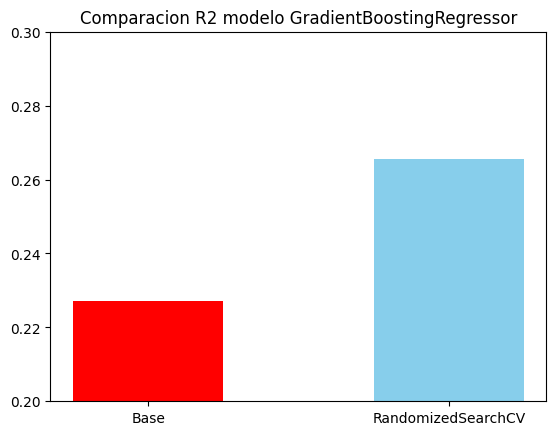

In [ ]:
plt.bar(x=['Base','RandomizedSearchCV'],height=[r2_base,r2_rs],width=0.5,color=['red','skyblue'])
plt.ylim(bottom=0.20,top = 0.3)
plt.title('Comparacion R2 modelo GradientBoostingRegressor')

In [ ]:
from sklearn.linear_model import  LinearRegression
#https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

modelo = LinearRegression()
help(modelo)

Help on LinearRegression in module sklearn.linear_model._base object:

class LinearRegression(sklearn.base.MultiOutputMixin, sklearn.base.RegressorMixin, LinearModel)
 |  LinearRegression(
 |      *,
 |      fit_intercept=True,
 |      copy_X=True,
 |      n_jobs=None,
 |      positive=False
 |  )
 |
 |  Ordinary least squares Linear Regression.
 |
 |  LinearRegression fits a linear model with coefficients w = (w1, ..., wp)
 |  to minimize the residual sum of squares between the observed targets in
 |  the dataset, and the targets predicted by the linear approximation.
 |
 |  Parameters
 |  ----------
 |  fit_intercept : bool, default=True
 |      Whether to calculate the intercept for this model. If set
 |      to False, no intercept will be used in calculations
 |      (i.e. data is expected to be centered).
 |
 |  copy_X : bool, default=True
 |      If True, X will be copied; else, it may be overwritten.
 |
 |  n_jobs : int, default=None
 |      The number of jobs to use for the com

In [ ]:
modelo.fit(X_train, y_train) #<<< entrenamiento

LinearRegression()

In [ ]:
#Una vez entrenado el modelo está listo para usarlo.
y_pred  = modelo.predict(X_test)
# Los métodos predict siempre devuelven un numpy array

In [ ]:
df_y_pred = pd.Series(y_pred)
df_y_pred
# Ya siendo una serie podemos explorar los resultados

,0
0,129.819609
1,133.287826
2,57.842548
3,81.369465
4,95.821023
...,...
267091,129.652220
267092,102.411074
267093,63.643015
267094,65.259131


In [ ]:
# Crear una copia de X_test para no modificar la variable original
test = X_test.copy()

# Asignar los valores predichos y los valores reales alineando sus arreglos
test['pred'] = y_pred
test['real'] = y_test.values

# Visualizar el DataFrame final
test

,distancia_grados,region_id,aoi_id,hora_dia,dia_semana,pred,real
1102557,0.024303,69,22267,9,0,129.819609,159.0
913834,0.020396,57,11671,8,5,133.287826,107.0
42574,0.026984,2,10291,19,1,57.842548,65.0
182664,0.027563,8,28165,17,5,81.369465,55.0
105320,0.016756,6,12454,14,6,95.821023,159.0
...,...,...,...,...,...,...,...
1469509,0.025104,92,31264,9,5,129.652220,89.0
169234,0.004972,8,12851,13,6,102.411074,256.0
861402,0.041036,52,8015,17,5,63.643015,72.0
106059,0.007227,6,15351,18,5,65.259131,129.0


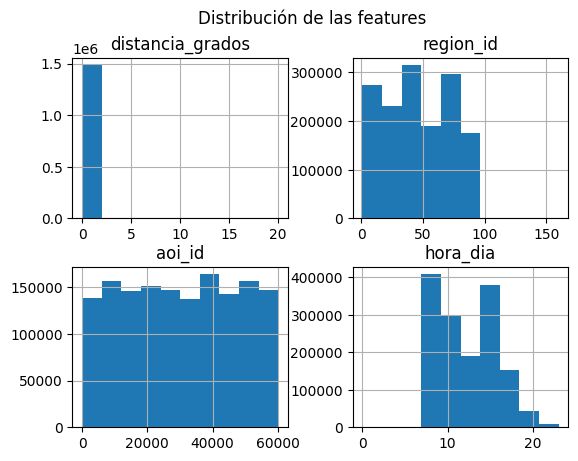

In [ ]:
# Definir la variable 'datos' seleccionando las columnas de interés de tu DataFrame
datos = df[['distancia_grados', 'region_id', 'aoi_id', 'hora_dia']]

# Cambiar 'features' para usar los nombres de las columnas en lugar de un rango numérico
features = datos.columns

# Generar el histograma
datos[features].hist()
plt.suptitle("Distribución de las features")
plt.show()

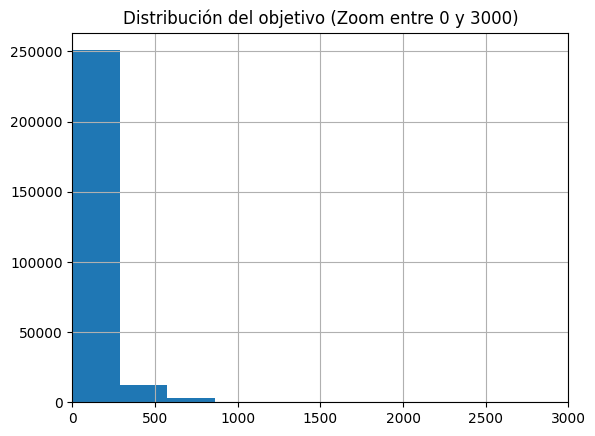

In [ ]:
# Aumentamos los intervalos y filtramos el rango visual del eje X
y_test.hist(bins=100)
plt.xlim(0, 3000)  # Ajusta el límite según la zona de interés
plt.title("Distribución del objetivo (Zoom entre 0 y 3000)")
plt.show()

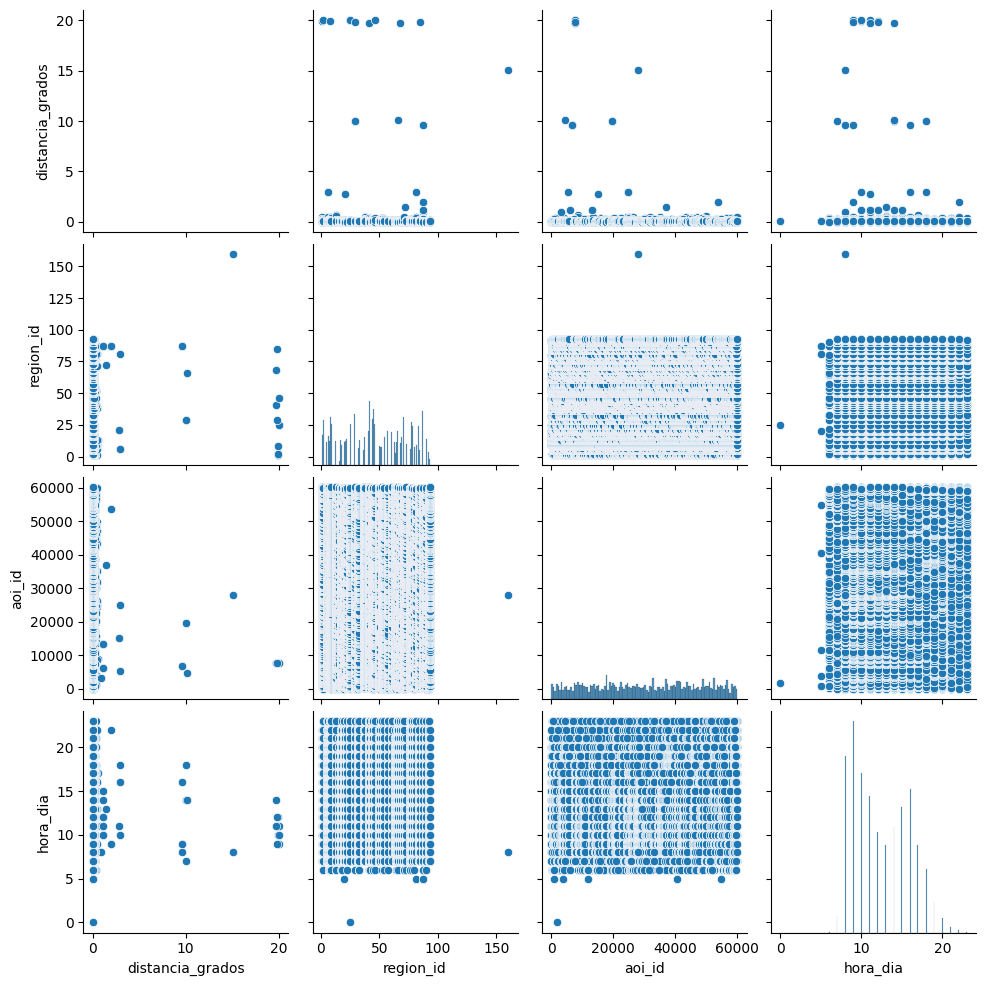

In [ ]:
sns.pairplot(datos, diag_kind="hist")
plt.show()

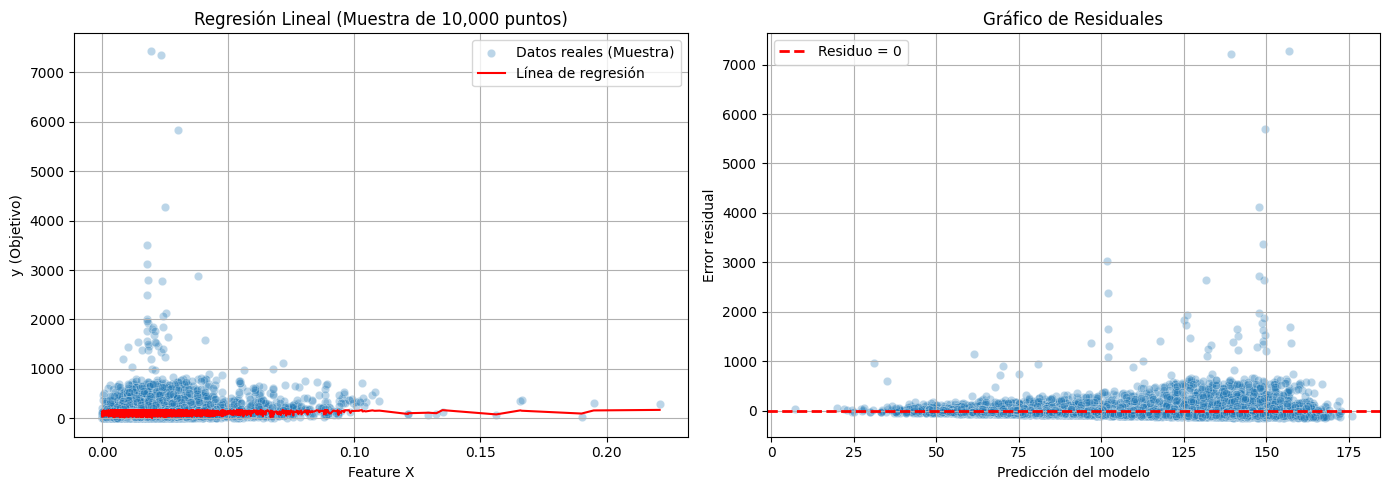

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

# 1. Entrenar el modelo con los datos completos
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 2. Tomar una muestra aleatoria razonable para graficar (10,000 puntos)
tamano_muestra = min(10000, len(X_test))

# Asegurar muestreo consistente tanto si es DataFrame/Series como si es NumPy array
if hasattr(X_test, "sample"):
    idx_muestra = X_test.sample(n=tamano_muestra, random_state=42).index
    X_test_sub = X_test.loc[idx_muestra]
    y_test_sub = y_test.loc[idx_muestra]
else:
    np.random.seed(42)
    idx_muestra = np.random.choice(len(X_test), size=tamano_muestra, replace=False)
    X_test_sub = X_test[idx_muestra]
    y_test_sub = y_test[idx_muestra]

# 3. Predicciones y cálculo de residuales sobre la muestra
y_pred_sub = modelo.predict(X_test_sub)
y_real_sub = y_test_sub.values if hasattr(y_test_sub, "values") else y_test_sub
residuales_sub = y_real_sub.flatten() - y_pred_sub.flatten()

# Seleccionar la primera feature para el eje X del primer gráfico
if hasattr(X_test_sub, "iloc"):
    x_graf = X_test_sub.iloc[:, 0].values
else:
    x_graf = X_test_sub[:, 0]

# 4. Crear subplots
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# --- Subplot 1: Gráfico de regresión (Muestra con alpha para evitar superposición) ---
sns.scatterplot(
    x=x_graf, y=y_real_sub.flatten(), ax=axs[0], alpha=0.3, label='Datos reales (Muestra)'
)
sns.lineplot(
    x=x_graf, y=y_pred_sub.flatten(), color='red', ax=axs[0], label='Línea de regresión'
)
axs[0].set_title(f'Regresión Lineal (Muestra de {tamano_muestra:,} puntos)')
axs[0].set_xlabel('Feature X')
axs[0].set_ylabel('y (Objetivo)')
axs[0].legend()
axs[0].grid(True)

# --- Subplot 2: Gráfico de residuales ---
sns.scatterplot(x=y_pred_sub.flatten(), y=residuales_sub, ax=axs[1], alpha=0.3)
axs[1].axhline(0, color='red', linestyle='--', linewidth=2, label='Residuo = 0')
axs[1].set_title('Gráfico de Residuales')
axs[1].set_xlabel('Predicción del modelo')
axs[1].set_ylabel('Error residual')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_percentage_error

# Calcular el MAPE
error_mape = mean_absolute_percentage_error(y_test, y_pred)
print(error_mape)

752700100163385.2


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Error Absoluto Medio (MAE) -> en las mismas unidades de tu variable
mae = mean_absolute_error(y_test, y_pred)

# Raíz del Error Cuadrático Medio (RMSE)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 77.6092
RMSE: 224.7151


In [ ]:
# =========================================================================
# RandomForestRegressor - Modelo final (Sil)
# Tener en cuanta que deben existir previamente: X_train, X_test, y_train, y_test (celda 24 del notebook)
# =========================================================================

# ---- Instanciar modelo base + K-Fold ----
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

modelo_rf_reg = RandomForestRegressor(random_state=42, n_jobs=-1)
kf = KFold(n_splits=5, shuffle=True, random_state=42) #Copiar el mismo que la celda 21 para que sean iguales




In [ ]:
# ---- Validación cruzada (K-Fold) dentro de train ---- Ramdom Forest
# Usamos la misma muestra reducida que usaron para GB, para que la comparación sea justa
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train, y_train, train_size=15000, random_state=42
)

cv_results_rf = cross_validate(
    modelo_rf_reg, X_train_sample, y_train_sample,
    cv=kf, scoring=['r2', 'neg_mean_absolute_error']
)

r2_cross_v_rf = cv_results_rf['test_r2'].mean()
mae_cross_v_rf = -cv_results_rf['test_neg_mean_absolute_error'].mean()

print("=== VALIDACIÓN CRUZADA - RandomForest (sobre Train Sample) ===")
print(f"R² promedio en K-Fold: {r2_cross_v_rf:.4f}")
print(f"MAE promedio en K-Fold: {mae_cross_v_rf:.2f}")




=== VALIDACIÓN CRUZADA - RandomForest (sobre Train Sample) ===
R² promedio en K-Fold: 0.1481
MAE promedio en K-Fold: 71.19


In [ ]:
# ---- Entrenamiento definitivo + evaluación en test ----Ramdom Forest
modelo_rf_reg.fit(X_train, y_train)
y_pred_rf = modelo_rf_reg.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("\n=== EVALUACIÓN FINAL - RandomForest (sobre Test completo) ===")
print(f"R² en Test: {r2_rf:.4f}")
print(f"MAE en Test: {mae_rf:.2f}")
print(f"RMSE en Test: {rmse_rf:.2f}")




In [ ]:
# ---- Búsqueda de hiperparámetros ---- Ramdom Forest
from sklearn.model_selection import RandomizedSearchCV

param_dist_rf = {
    "n_estimators": [200, 300, 500],
    "max_depth": [8, 12, 15, 20, None],
    "min_samples_leaf": [1, 3, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
}

rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

search_rf = RandomizedSearchCV(
    rf_base,
    param_distributions=param_dist_rf,
    n_iter=15,
    cv=kf,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
search_rf.fit(X_train_sample, y_train_sample)

print("Mejores hiperparámetros encontrados:", search_rf.best_params_) #esto me va a dar una lista, que tengo que colocar de nuevo en el código,
# volver al paso de la definicióm del modelo



In [ ]:

# ---- Entrenar versión optimizada y comparar ---- Ramdom Forest
modelo_rf_reg_v2 = RandomForestRegressor(**search_rf.best_params_, random_state=42, n_jobs=-1)
modelo_rf_reg_v2.fit(X_train, y_train)
y_pred_rf_v2 = modelo_rf_reg_v2.predict(X_test)

r2_rf_v2 = r2_score(y_test, y_pred_rf_v2)
mae_rf_v2 = mean_absolute_error(y_test, y_pred_rf_v2)

print("\n=== Comparación final de modelos ===")
print(f"R² base:               {r2_base:.4f}   (GradientBoosting)")
print(f"R² RandomForest:       {r2_rf:.4f}")
print(f"R² RandomForest (RS):  {r2_rf_v2:.4f}")
print(f"MAE base:              {mae_base:.2f}   (GradientBoosting)")
print(f"MAE RandomForest:      {mae_rf:.2f}")
print(f"MAE RandomForest (RS): {mae_rf_v2:.2f}")